The Xception model is a deep convolutional neural network (CNN) that stands for "Extreme Inception." It is an improvement over the Inception architecture, utilizing depthwise separable convolutions to reduce computational cost while maintaining high performance.

In [1]:
import tensorflow as tf
from tensorflow.keras.applications import Xception
from tensorflow.keras import layers, models
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, RandomFlip, RandomRotation, RandomZoom
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
import matplotlib.pyplot as plt

In [3]:
# === 1. Setup ===
dataset_path = "../../../wheat_256px-dataset"
img_size = (256, 256)  # TODO Xception requires 299x299 input
batch_size = 32
num_classes = 5
seed = 42

# === 2. Load and Split Dataset ===
train_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    dataset_path,
    image_size=img_size,
    batch_size=batch_size,
    color_mode="rgb",
    validation_split=0.4,
    subset="training",
    seed=seed
)

val_test_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    dataset_path,
    image_size=img_size,
    batch_size=batch_size,
    color_mode="rgb",
    validation_split=0.4,
    subset="validation",
    seed=seed
)

# Split validation into validation and test
val_dataset = val_test_dataset.take(len(val_test_dataset) // 2)
test_dataset = val_test_dataset.skip(len(val_test_dataset) // 2)

# === 3. Data Augmentation ===
data_augmentation = tf.keras.Sequential([
    RandomFlip("horizontal_and_vertical"),
    RandomRotation(0.2),
    RandomZoom(0.2),
])

Found 19159 files belonging to 5 classes.
Using 11496 files for training.
Found 19159 files belonging to 5 classes.
Using 7663 files for validation.


Found 19159 files belonging to 5 classes.
Using 11496 files for training.


2025-04-04 11:01:28.582002: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M1 Pro
2025-04-04 11:01:28.582061: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2025-04-04 11:01:28.582069: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.33 GB
2025-04-04 11:01:28.582323: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2025-04-04 11:01:28.582351: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Found 19159 files belonging to 5 classes.
Using 7663 files for validation.
Epoch 1/30


2025-04-04 11:01:31.235006: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


360/360 ━━━━━━━━━━━━━━━━━━━━ 162s 440ms/step - accuracy: 0.4246 - loss: 1.3873 - val_accuracy: 0.6583 - val_loss: 0.8826 - learning_rate: 1.0000e-04
Epoch 2/30
360/360 ━━━━━━━━━━━━━━━━━━━━ 156s 435ms/step - accuracy: 0.6232 - loss: 0.9618 - val_accuracy: 0.7086 - val_loss: 0.7843 - learning_rate: 1.0000e-04
Epoch 3/30
360/360 ━━━━━━━━━━━━━━━━━━━━ 157s 436ms/step - accuracy: 0.6654 - loss: 0.8720 - val_accuracy: 0.7336 - val_loss: 0.7217 - learning_rate: 1.0000e-04
Epoch 4/30
360/360 ━━━━━━━━━━━━━━━━━━━━ 157s 436ms/step - accuracy: 0.6952 - loss: 0.8167 - val_accuracy: 0.7521 - val_loss: 0.6984 - learning_rate: 1.0000e-04
Epoch 5/30
360/360 ━━━━━━━━━━━━━━━━━━━━ 156s 434ms/step - accuracy: 0.7092 - loss: 0.7584 - val_accuracy: 0.7521 - val_loss: 0.6744 - learning_rate: 1.0000e-04
Epoch 6/30
360/360 ━━━━━━━━━━━━━━━━━━━━ 156s 435ms/step - accuracy: 0.7198 - loss: 0.7363 - val_accuracy: 0.7641 - val_loss: 0.6441 - learning_rate: 1.0000e-04
Epoch 7/30
360/360 ━━━━━━━━━━━━━━━━━━━━ 157s 436ms/

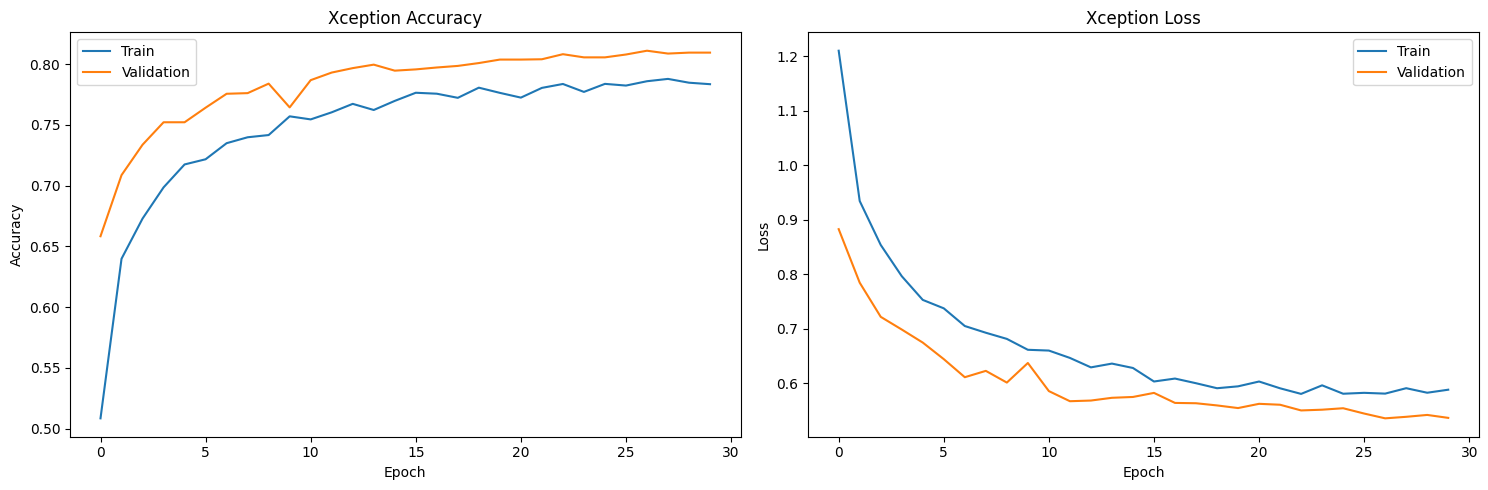

In [ ]:
# === 4. Load Xception with Proper Preprocessing ===
base_model = Xception(
    weights='imagenet',
    include_top=False,
    input_shape=(256, 256, 3))
base_model.trainable = False  # Freeze initially

# === 5. Build Model ===
inputs = tf.keras.Input(shape=(256, 256, 3))
x = data_augmentation(inputs)
x = tf.keras.applications.xception.preprocess_input(x)  # Xception-specific preprocessing
x = base_model(x, training=False)
x = GlobalAveragePooling2D()(x)
x = Dense(512, activation='relu')(x)  # Larger dense layer for Xception
x = Dropout(0.6)(x)
outputs = Dense(num_classes, activation='softmax')(x)
model = models.Model(inputs, outputs)

# === 6. Compile with Xception-Optimized Settings ===
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# === 7. Callbacks ===
callbacks = [
    EarlyStopping(patience=5, monitor='val_accuracy', restore_best_weights=True),
    ModelCheckpoint('xception_best.keras', monitor='val_accuracy', save_best_only=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2)
]

# === 8. Training ===
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=30,
    callbacks=callbacks
)

# === 9. Plot Training Curves ===
plt.figure(figsize=(15, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title('Xception Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Validation')
plt.title('Xception Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

#### Prediction evaluation
Model Loading: The best model is loaded from the saved file (<best_model>.keras).
- Data Preparation: Test images and labels are extracted from the test dataset for evaluation.
- Predictions: The model predicts class probabilities for the test images, and the predicted labels are determined by selecting the class with the highest probability.
- Metrics Calculation: Key metrics such as accuracy, precision, recall, and F1-score are computed using the true and predicted labels.
- Classification Report: A detailed classification report is generated, showing precision, recall, and F1-score for each class.
- Confusion Matrix: A confusion matrix is plotted using Seaborn to visualize the model's performance across different classes.
- Sample Predictions: Random test samples are displayed with their true labels, predicted labels, and confidence scores to provide a qualitative assessment of the model's predictions.

2025-04-07 14:23:04.238855: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
2025-04-07 14:23:09.305571: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


120/120 ━━━━━━━━━━━━━━━━━━━━ 39s 304ms/step

Classification Report:
              precision    recall  f1-score   support

  brown_rust       0.68      0.87      0.76       486
     healthy       0.80      0.77      0.78       449
      mildew       0.93      0.64      0.76       597
    septoria       0.85      0.86      0.85      1394
 yellow_rust       0.74      0.78      0.76       897

    accuracy                           0.80      3823
   macro avg       0.80      0.78      0.78      3823
weighted avg       0.81      0.80      0.80      3823


Additional Metrics:
Accuracy: 79.65%
Precision: 80.79%
Recall: 79.65%
F1-Score: 79.63%


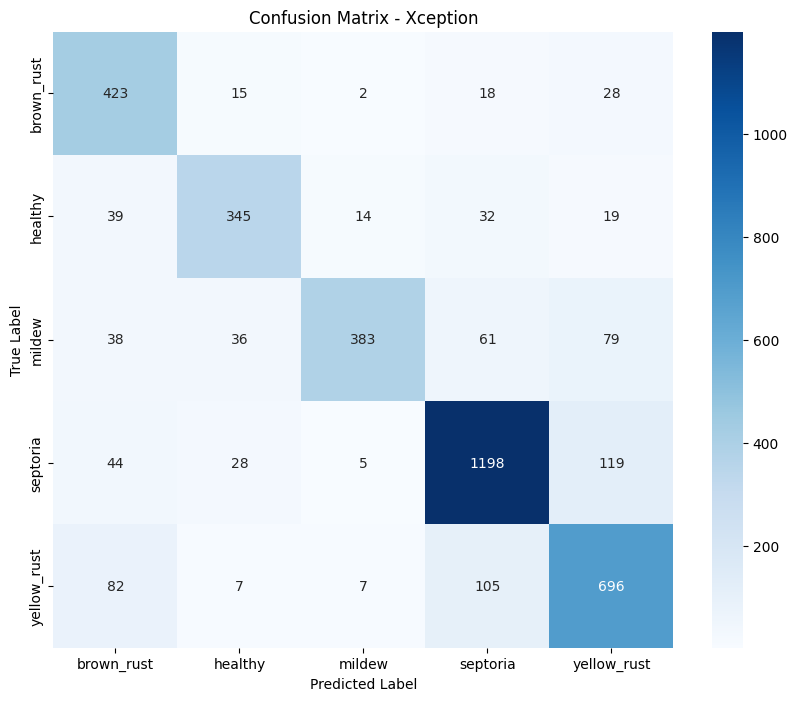

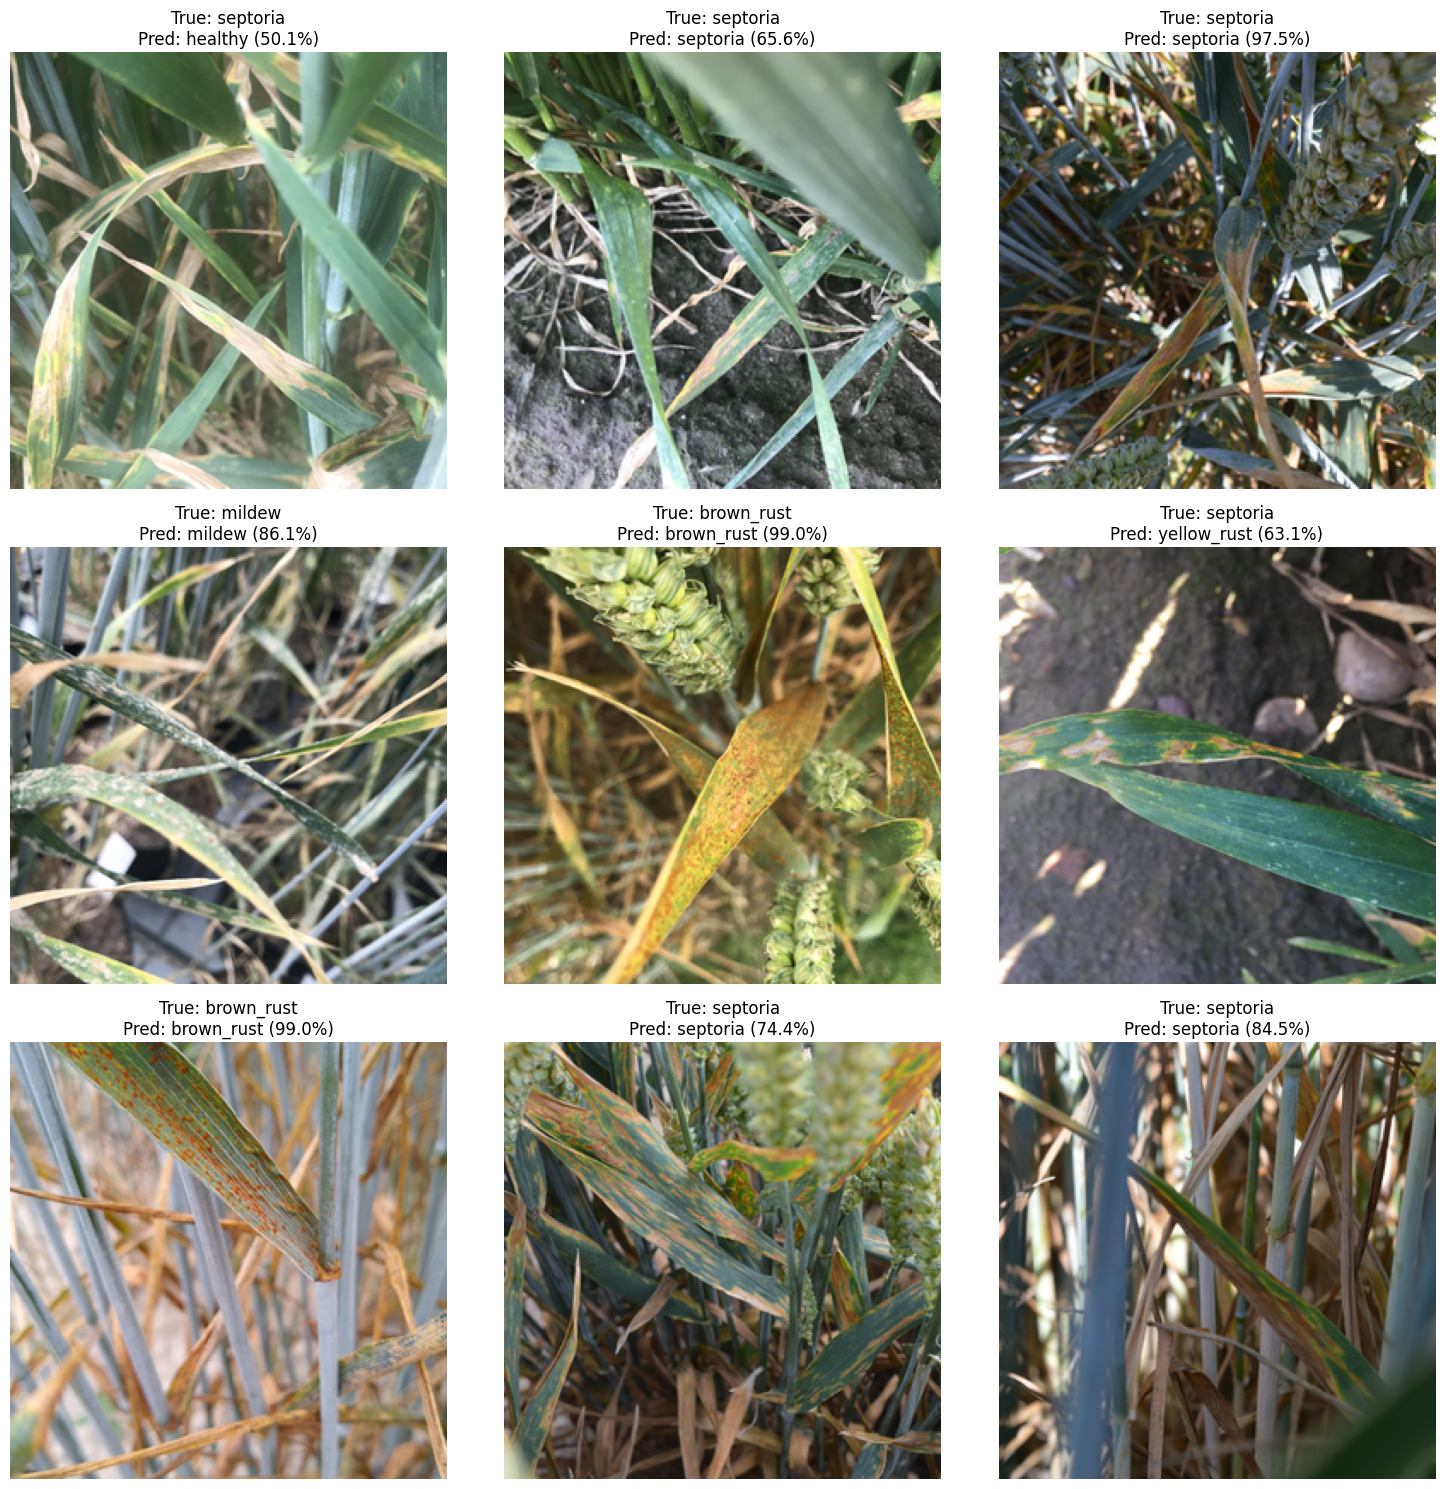

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score
import seaborn as sns

model = tf.keras.models.load_model('xception_best.keras')
class_names = train_dataset.class_names

test_images, test_labels = [], []
for img, lbl in test_dataset.unbatch():
    test_images.append(img.numpy())
    test_labels.append(lbl.numpy())

test_images = np.array(test_images)
test_labels = np.array(test_labels)

# predictions
predictions = model.predict(test_images, verbose=1)
predicted_labels = np.argmax(predictions, axis=1)

# metrics
accuracy = accuracy_score(test_labels, predicted_labels)
precision = precision_score(test_labels, predicted_labels, average='weighted')
recall = recall_score(test_labels, predicted_labels, average='weighted')
f1 = f1_score(test_labels, predicted_labels, average='weighted')

print("\nClassification Report:")
print(classification_report(test_labels, predicted_labels, target_names=class_names))

print("\nAdditional Metrics:")
print(f"Accuracy: {accuracy:.2%}")
print(f"Precision: {precision:.2%}")
print(f"Recall: {recall:.2%}")
print(f"F1-Score: {f1:.2%}")

plt.figure(figsize=(10, 8))
cm = confusion_matrix(test_labels, predicted_labels)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)
plt.title('Confusion Matrix - Xception')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

plt.figure(figsize=(15, 15))
for i in range(9):  # Show 9 random samples
    ax = plt.subplot(3, 3, i+1)
    plt.imshow(test_images[i].astype('uint8'))  # Assumes RGB images
    true_label = class_names[test_labels[i]]
    pred_label = class_names[predicted_labels[i]]
    confidence = np.max(predictions[i]) * 100
    plt.title(f"True: {true_label}\nPred: {pred_label} ({confidence:.1f}%)")
    plt.axis('off')
plt.tight_layout()
plt.show()